<a href="https://colab.research.google.com/github/JB-GB/AI_for_Biomedical_Engineers/blob/main/AF5_Convolutional_Neural_Network.CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Artificial Intelligence**
## *Assignment 5: Convolutional Neural Network*
### Team:
#### Adrián Noriega Solís ID: 2111735
#### Aldo Reynold Alvarado Pérez ID: 2107251
#### Julieta Anahí Martínez Rangel ID: 2106210
#### Jorge Augusto Becerra Cifuentes ID: 2177839
#### Karla Ximena Rendón Calderón ID: 2044499

---
Class day & hour:
Tuesday at N4

Step 1: Import Libraries

In [ ]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import datasets, layers, models

Step 2: Load Data

In [ ]:
#Descargamos los datos que nos proporcionaron en la tarea
#(Numeros del 0-9 escritos a mano)
keras.datasets.mnist.load_data(path="mnist.npz")




((array([[[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         ...,
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0

Step 3: Data preprocessing

In [ ]:
#Dividimos en dataset en entrenamiento y testeo
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

#Comprobamos q hay 60,000 imagenes de 28x28 pixeles para entrenar
assert x_train.shape == (60000, 28, 28)

#Comprobamos q hay 10,000 imagenes de 28x28 pixeles para probar
assert x_test.shape == (10000, 28, 28)

#Comprobamos que existen 60,000 etiquetas de entrenamiento
assert y_train.shape == (60000,)

#Comprobamos que existen 10,000 etiquetas de testeo
assert y_test.shape == (10000,)

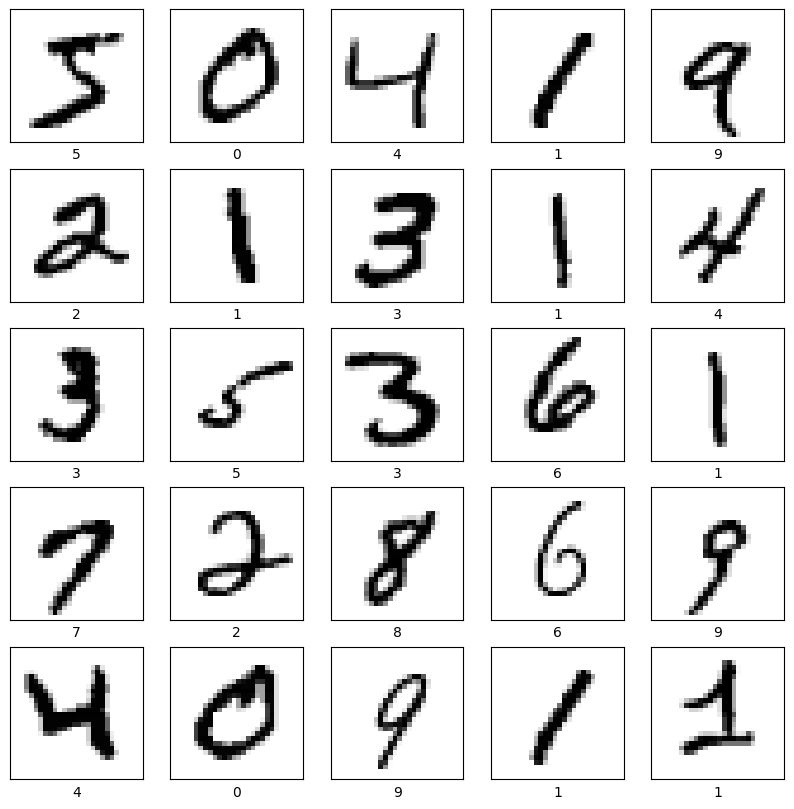

In [ ]:
#Damos nombre a las clases
class_names = ['0', '1', '2', '3', '4',
               '5', '6', '7', '8', '9']
#Esto solo crea el espacio en blanco para poner 25 imagenes de ejemplo
plt.figure(figsize=(10,10))
#Sacamos 25 imagenes
for i in range(25):
#Dividimos el espacio en 5 fialas y 5 columnas :D
    plt.subplot(5,5,i+1)
#Quitamos datos de ubicación de los pixeles y la cuadricula
#(basicamente hacen que no se vea como plano cartesiano lol)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
#Esto pone la imagen "i" sobre uno de los cuadros, la parte del cmap
#lo que hace es poner el 0 del pixel como blanco y el 255 como negro
    plt.imshow(x_train[i], cmap=plt.cm.binary)
#En y_train[i] tenemos la etiqueta de los numeros, asi que la ponemos
#debajo de cada imagen
    plt.xlabel(class_names[y_train[i]])
plt.show()

In [ ]:
#Cambiamos las dimensiones de las imagenes, 60,000 imagenes de 28x28
#el 1 extra es para el canal del color blanco/negro para train y test
#tambien normalizamos dividiendo entre 255
x_train = x_train.reshape((60000, 28, 28, 1)) / 255.0
x_test = x_test.reshape((10000, 28, 28, 1)) / 255.0

Step 4: Select and train the model

In [ ]:
#Esto crea la CNN para sacar las caracteristiacs de todo

#Crea un modelo vacío de tipo Sequential, donde las capas se apilan una tras otra
#y la salida de cada una es la entrada de la siguiente
model = models.Sequential()

#Tenemos 32 filtros, estos son de 3x3 pixeles, estos se van
#pasando por toda la imagen y la hacen más pequeña, la parte de relu hace que
#todos los valores negativos se hagan 0, la parte del input es de q las imagenes
#son de 28x28 pixeles y el 1 es por el color igual q arriba
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)))
#Reduce el tamaño de la imagen a la mitad.
#Toma bloques de 2×2 píxeles y se queda solo con el valor máximo de cada uno.
model.add(layers.MaxPooling2D((2, 2)))
#Lo mismo pero ahora con 64 filtros y pues obvio aqui no hay input
#por que es el hidden layer
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
#Ahora si es lo mismo q el de arriba
model.add(layers.MaxPooling2D((2, 2)))
#X2 lo mismo q el otro
model.add(layers.Conv2D(64, (3, 3), activation='relu'))

In [ ]:
#Layer (type): nombre y tipo de cada capa. Los números (conv2d_6, conv2d_7...)
#son contadores automáticos de Keras.

#Output Shape: la forma de los datos al salir de la capa.
#El None es el tamaño del lote (batch), que queda libre porque puedes entrenar
#con cualquier cantidad de imágenes a la vez, los numeros son la cantidad de pixeles
#(ahorita explico los numeros)

#Param #: cantidad de parámetros que la capa aprende durante el entrenamiento.

#La fórmula para una capa convolucional es:
#(alto × ancho × canales de entrada + 1) × número de filtros
#El +1 es el sesgo (bias) de cada filtro.

#Una Conv2d le quita 2 píxeles al alto y al ancho. osea hace -2
#El número de canales (la tercera dimensión)
#lo define la cantidad de filtros de cada capa: 32, 64 y 64.
#(crecen al reducir el tamaño de pixeles)

#Las capas de MaxPooling tienen 0 parámetros porque solo toman el máximo
#de cada bloque; no hay nada que ajustar.
#El MaxPooling2d quita la mitad, 2×2 divide entre 2 y redondea hacia abajo.

#Los parametros totales son la suma de todos los parametros
#Los entrenables son los q se actualizan durante el entrenamiento osea todos
#Y los no entregables son 0 pq no hay nada pre-entrenado o sin usarse

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,744 (217.75 KB)

 Trainable params: 55,744 (217.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Aqui ya sacamos las caracteristicas, ahora vamos a dar las bases de prediccion

#El Flatten como dice aplana el 3x3x64 son 3 dimensiones y el sigueinte paso
#la capa Dense solo acepta de 1 dimensión
model.add(layers.Flatten())
#La capa Densa (con 64 neuronas) significa que esta totalmente conectada osea
#los 576 valores (3x3x64 = 576) con todoos los otros valores con sus pesos para
#aprender las caracteristicas importantes usa relu para lo mismo que las convoluciones
#aqui en total se crean 64x(576+1) parametros, osea 36,928
model.add(layers.Dense(64, activation='relu'))
#Capa de salida con 10 neuronas, una por cada dígito (0 al 9).
#Parámetros: (64+1)×10 = 650.
model.add(layers.Dense(10))

In [ ]:
#Vemos de nuevo y ahora completo el modelo
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,322 (364.54 KB)

 Trainable params: 93,322 (364.54 KB)

 Non-trainable params: 0 (0.00 B)

Step 5: Train the model

In [ ]:
#Comprobamos q la normalización se haya realizado 1 SOLA VEZ
print(x_train.shape, x_train.dtype, x_train.max())

(60000, 28, 28, 1) float64 1.0


In [ ]:
#Define el optimizador, el algoritmo ajusta los 93,322 parámetros para reducir el error.
#Adam es la opción mas común adapta la velocidad de
#aprendizaje de cada parámetro automáticamente.
#La parte de loss (no el meme we), dice que tan equivocado está
#CategoricalCrossentropy: se usa cuando hay varias clases (aquí los numeros 0-9).
#Sparse: indica que las etiquetas son números enteros (5, 3, ...) y no vectores
#en nuestro caso pq pues las respuestas son lit los numeros
#from_logits=True: le dice que la última capa Dense(10) entrega valores crudos
#(sin softmax), así que aplique el softmax internamente. lo q hace el softmax es
#q transforma el valor de la ultima capa en probabilidades
#Accuracy pide mostrar la exactitud (porcentaje de aciertos) durante el entrenamiento.
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])
#Emepezamos el entrenamiento con las 60,000 imagenes
#Epochs es q repite el entrenamiento, en este caso 10 veces
#history guarda la perdida y exactitud de cada epoca
history = model.fit(x_train, y_train, epochs=10,
                    validation_data=(x_test, y_test))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 69s 36ms/step - accuracy: 0.9549 - loss: 0.1455 - val_accuracy: 0.9847 - val_loss: 0.0498
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 68s 37ms/step - accuracy: 0.9854 - loss: 0.0473 - val_accuracy: 0.9898 - val_loss: 0.0316
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 66s 35ms/step - accuracy: 0.9899 - loss: 0.0331 - val_accuracy: 0.9903 - val_loss: 0.0318
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 66s 35ms/step - accuracy: 0.9922 - loss: 0.0247 - val_accuracy: 0.9913 - val_loss: 0.0294
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 80s 34ms/step - accuracy: 0.9936 - loss: 0.0201 - val_accuracy: 0.9902 - val_loss: 0.0330
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 81s 34ms/step - accuracy: 0.9948 - loss: 0.0161 - val_accuracy: 0.9907 - val_loss: 0.0323
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 34ms/step - accuracy: 0.9958 - loss: 0.0130 - val_accuracy: 0.9919 - val_loss: 0.0280
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 34ms/step - accuracy: 0.9966 -

313/313 - 3s - 10ms/step - accuracy: 0.9933 - loss: 0.0316


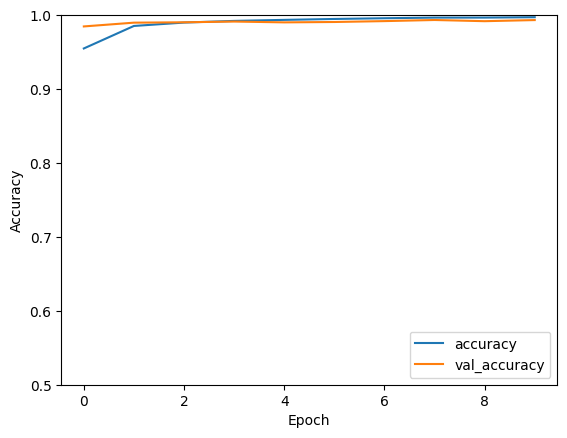

In [ ]:
#Dibuja la exactitud de entrenamiento de cada época. history.history
#es un diccionario que Keras llenó durante fit, y ['accuracy'] es la lista con 10 valores.
#El eje X son las épocas y el eje Y la exactitud. label es el nombre que aparecerá en la leyenda.
plt.plot(history.history['accuracy'], label='accuracy')
#Dibuja en la misma figura la exactitud de validación (sobre las imágenes de prueba).
#Comparar ambas curvas permite detectar sobreajuste.
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
#Ponen los títulos de los ejes: época en X, exactitud en Y
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
#Limita el eje Y al rango de 0.5 a 1.
#Así la gráfica se enfoca en la zona donde están los valores
plt.ylim([0.5, 1])
#Muestra la leyenda con los nombres de las dos curvas
plt.legend(loc='lower right')
#Evalúa el modelo ya entrenado con las 10,000 imágenes de prueba y devuelve dos valores
#test_loss: la pérdida final.
#test_acc: la exactitud final.
#verbose=2 hace que imprima una sola línea de resultado en vez de la barra de progreso.
test_loss, test_acc = model.evaluate(x_test,  y_test,verbose=2)
#En el output, Son 313 pasos porque 10,000 / 32 ≈ 313

In [ ]:
#Esto dice cuanto porcentaje tiene de acierto
print(test_acc)

0.9933000206947327


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step
[2.5778511e-12 1.4649425e-09 6.8458373e-12 9.5306528e-14 4.4495786e-11
 9.0532989e-14 7.7595345e-17 9.9999994e-01 5.8460550e-13 7.5734867e-09]
7
7


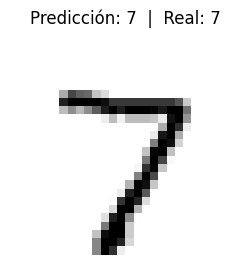

In [ ]:
#Ahora vamos a hacer 5 predicciones con el modelo

#Crea un modelo nuevo que une tu model entrenado con una capa Softmax al final.
#Lo que habiamos dicho q el modelo solo da la probabilidad pero el softmax da
#el numero especifico
probability_model = tf.keras.Sequential([model, tf.keras.layers.Softmax()])
#Le pasa las 10,000 imágenes de prueba y obtiene las predicciones.
predictions = probability_model.predict(x_test)
#Las 10 probabilidades, la más grande representa la respuesta
print(predictions[0])
#Numero predicho
print(predictions[0].argmax())
#Numero real
print(y_test[0])
#Aqui de nuevo hacemos lo de mostrar la imagen pero agregando el titulo con la
#respuesta del modelo y el real
plt.figure(figsize=(3, 3))
plt.imshow(x_test[0].reshape(28, 28), cmap=plt.cm.binary)
plt.title(f"Predicción: {predictions[0].argmax()}  |  Real: {y_test[0]}")
plt.axis('off')
plt.show()

[1.6719885e-14 9.8639006e-14 9.9999994e-01 7.0082838e-17 1.9219747e-14
 1.7374755e-22 1.8203971e-14 1.0086535e-17 3.6742519e-15 2.4129686e-18]
2
2


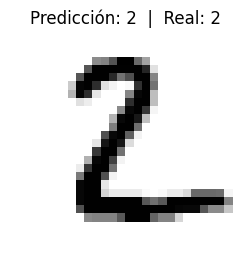

In [ ]:
#Predicción 2
print(predictions[1])
print(predictions[1].argmax())
print(y_test[1])
plt.figure(figsize=(3, 3))
plt.imshow(x_test[1].reshape(28, 28), cmap=plt.cm.binary)
plt.title(f"Predicción: {predictions[1].argmax()}  |  Real: {y_test[1]}")
plt.axis('off')
plt.show()

[2.12105825e-14 1.44352087e-13 1.34802048e-11 1.23131697e-14
 9.99999702e-01 1.68322984e-13 1.18231239e-12 9.77108883e-08
 7.10591724e-11 1.16905596e-07]
4
4


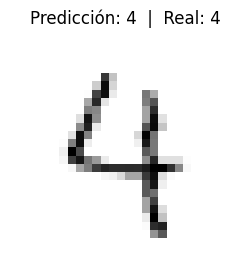

In [ ]:
#Predicción 3
print(predictions[24])
print(predictions[24].argmax())
print(y_test[24])
plt.figure(figsize=(3, 3))
plt.imshow(x_test[24].reshape(28, 28), cmap=plt.cm.binary)
plt.title(f"Predicción: {predictions[24].argmax()}  |  Real: {y_test[24]}")
plt.axis('off')
plt.show()

[3.3158471e-19 6.8334326e-19 1.5537245e-22 3.8298348e-10 8.8010985e-16
 9.9999994e-01 8.3414820e-18 2.0445513e-17 2.3754336e-13 2.3640783e-14]
5
5


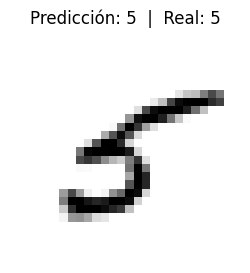

In [ ]:
#Predicción 4
print(predictions[9626])
print(predictions[9626].argmax())
print(y_test[9626])
plt.figure(figsize=(3, 3))
plt.imshow(x_test[9626].reshape(28, 28), cmap=plt.cm.binary)
plt.title(f"Predicción: {predictions[9626].argmax()}  |  Real: {y_test[9626]}")
plt.axis('off')
plt.show()

[2.1115385e-16 4.6036548e-17 1.4078568e-13 6.3767286e-19 2.3066501e-15
 1.7232990e-12 9.9999994e-01 1.0908401e-23 5.5947881e-16 2.5417346e-21]
6
6


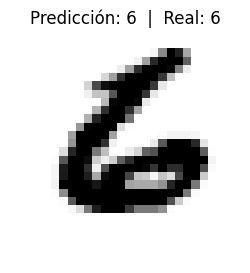

In [ ]:
#Predicción 5
print(predictions[-1])
print(predictions[-1].argmax())
print(y_test[-1])
plt.figure(figsize=(3, 3))
plt.imshow(x_test[-1].reshape(28, 28), cmap=plt.cm.binary)
plt.title(f"Predicción: {predictions[-1].argmax()}  |  Real: {y_test[-1]}")
plt.axis('off')
plt.show()

In [ ]:
#Calcula cuanto se equivoco, esto no es parte de la tarea solo tenía curiosidad
import numpy as np
errores = np.where(predictions.argmax(axis=1) != y_test)[0]
print(f"Errores: {len(errores)} de 10000")

Errores: 67 de 10000
